# Bank Transaction Fraud Detection Using Apache Spark and PySpark

## 1. Introduction

Digital payment systems and online banking platforms handle massive transaction volumes daily, making real-time fraud detection essential for financial security. Fraudulent activities introduce severe financial losses and erode consumer trust. This project analyzes large-scale bank transaction data and explores distributed machine-learning techniques using Apache Spark and PySpark to detect suspicious fraudulent behavior and analyze financial spending patterns.

## 2. Objectives

- Load and inspect bank transaction datasets using PySpark.
- Analyze data quality, missing values, and duplicate records.
- Clean and transform data for distributed analysis.
- Perform distributed data operations using Apache Spark.
- Visualize the dataset using charts and correlation heatmaps.
- Apply the machine-learning algorithms listed in Unit VI:
  - Unsupervised: K-Means Clustering
  - Supervised Regression: Linear Regression
  - Supervised Classification: Logistic Regression, Decision Tree, Support Vector Machine (SVM), and Naive Bayes
- Evaluate models using the appropriate performance metrics (Confusion Matrix, $R^2$, RMSE, MAE, Silhouette Score).

## 3. Tools and Technologies

- Python
- Apache Spark and PySpark
- Jupyter Notebook
- Matplotlib and Seaborn
- Spark MLlib

## 4. Project Overview

**Objective:** Analyze bank transaction patterns and develop machine learning approaches to identify fraudulent transactions and predict transaction values.

**Tools:** Python, Apache Spark, PySpark, Jupyter Notebook, Matplotlib, and Seaborn.

**Workflow:** Data loading → Data quality analysis (nulls & duplicates) → Exploratory data analysis → Data cleaning & transformation → Visualization → Machine learning → Model evaluation.

**Dataset:** `Bank_Transaction_Fraud_Detection.csv` (200,000 records, 24 columns).

**Target variables:** `Is_Fraud` (Classification: `1` represents a fraudulent transaction and `0` represents a legitimate transaction) and `Transaction_Amount` (Regression target).


### Step 1: Spark Environment Initialization

In [1]:
import os
import sys

os.environ["JAVA_HOME"] = r"C:\Program Files\Java\jdk1.8.0_501"
os.environ["SPARK_HOME"] = r"C:\Spark"
os.environ["HADOOP_HOME"] = r"C:\Spark"
os.environ["PATH"] = os.path.join(os.environ["JAVA_HOME"], "bin") + ";" + \
                     os.path.join(os.environ["SPARK_HOME"], "bin") + ";" + \
                     os.environ.get("PATH", "")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, hour, when, count, avg, sum

spark = SparkSession.builder \
    .master("local[*]") \
    .appName("Bank_Transaction_Fraud_Detection") \
    .config("spark.driver.memory", "2g") \
    .getOrCreate()

spark.sparkContext.setLogLevel("ERROR")

print("SparkSession initialized successfully!")
print("Spark Version:", spark.version)


SparkSession initialized successfully!
Spark Version: 3.5.9


### Step 2: Data Loading and Initial Inspection

In [2]:
df = spark.read.csv("Bank_Transaction_Fraud_Detection.csv", header=True, inferSchema=True)

print(f"Total Rows    : {df.count()}")
print(f"Total Columns : {len(df.columns)}")

df.printSchema()
df.show(5)


Total Rows    : 200000
Total Columns : 24
root
 |-- Customer_ID: string (nullable = true)
 |-- Customer_Name: string (nullable = true)
 |-- Gender: string (nullable = true)
 |-- Age: integer (nullable = true)
 |-- State: string (nullable = true)
 |-- City: string (nullable = true)
 |-- Bank_Branch: string (nullable = true)
 |-- Account_Type: string (nullable = true)
 |-- Transaction_ID: string (nullable = true)
 |-- Transaction_Date: string (nullable = true)
 |-- Transaction_Time: timestamp (nullable = true)
 |-- Transaction_Amount: double (nullable = true)
 |-- Merchant_ID: string (nullable = true)
 |-- Transaction_Type: string (nullable = true)
 |-- Merchant_Category: string (nullable = true)
 |-- Account_Balance: double (nullable = true)
 |-- Transaction_Device: string (nullable = true)
 |-- Transaction_Location: string (nullable = true)
 |-- Device_Type: string (nullable = true)
 |-- Is_Fraud: integer (nullable = true)
 |-- Transaction_Currency: string (nullable = true)
 |-- Custom

+--------------------+-------------------+------+---+-----------+------------------+--------------------+------------+--------------------+----------------+-------------------+------------------+--------------------+----------------+-----------------+---------------+------------------+--------------------+-----------+--------+--------------------+----------------+-----------------------+--------------------+
|         Customer_ID|      Customer_Name|Gender|Age|      State|              City|         Bank_Branch|Account_Type|      Transaction_ID|Transaction_Date|   Transaction_Time|Transaction_Amount|         Merchant_ID|Transaction_Type|Merchant_Category|Account_Balance|Transaction_Device|Transaction_Location|Device_Type|Is_Fraud|Transaction_Currency|Customer_Contact|Transaction_Description|      Customer_Email|
+--------------------+-------------------+------+---+-----------+------------------+--------------------+------------+--------------------+----------------+-------------------+

### Step 3: Data Quality Analysis: Missing Values and Duplicate Records
We inspect the dataset for potential data quality issues, auditing missing/null values across all columns and verifying if duplicate transaction records exist.


In [3]:
# Check for missing/null values in all columns
null_counts = df.select([count(when(col(c).isNull(), c)).alias(c) for c in df.columns])
null_counts.show()

# Check for duplicate records
total_records = df.count()
distinct_records = df.dropDuplicates().count()
duplicate_records = total_records - distinct_records

print(f"Total Records     : {total_records}")
print(f"Distinct Records  : {distinct_records}")
print(f"Duplicate Records : {duplicate_records}")


+-----------+-------------+------+---+-----+----+-----------+------------+--------------+----------------+----------------+------------------+-----------+----------------+-----------------+---------------+------------------+--------------------+-----------+--------+--------------------+----------------+-----------------------+--------------+
|Customer_ID|Customer_Name|Gender|Age|State|City|Bank_Branch|Account_Type|Transaction_ID|Transaction_Date|Transaction_Time|Transaction_Amount|Merchant_ID|Transaction_Type|Merchant_Category|Account_Balance|Transaction_Device|Transaction_Location|Device_Type|Is_Fraud|Transaction_Currency|Customer_Contact|Transaction_Description|Customer_Email|
+-----------+-------------+------+---+-----+----+-----------+------------+--------------+----------------+----------------+------------------+-----------+----------------+-----------------+---------------+------------------+--------------------+-----------+--------+--------------------+----------------+--------

Total Records     : 200000
Distinct Records  : 200000
Duplicate Records : 0


### Step 4: Exploratory Data Analysis & Relationship Exploration
Before training models, we analyze key statistical distributions and examine how transaction attributes relate to fraud occurrence.


In [4]:
# Summary statistics of primary numerical attributes
df.select("Age", "Transaction_Amount", "Account_Balance").describe().show()

# Target class distribution (Legitimate vs Fraud)
class_distribution = df.groupBy("Is_Fraud") \
                       .agg(count("*").alias("Record_Count"), \
                            (count("*") / total_records * 100).cast("decimal(5,2)").alias("Percentage_%"))
class_distribution.show()

# Fraud relationship by Transaction Type
df.groupBy("Transaction_Type") \
  .agg(count("*").alias("Total_Transactions"), \
       sum("Is_Fraud").alias("Fraud_Cases"), \
       (avg("Is_Fraud") * 100).cast("decimal(5,2)").alias("Fraud_Rate_%")) \
  .orderBy(col("Fraud_Rate_%").desc()) \
  .show()

# Fraud relationship by Device Type
df.groupBy("Device_Type") \
  .agg(count("*").alias("Total_Transactions"), \
       sum("Is_Fraud").alias("Fraud_Cases"), \
       (avg("Is_Fraud") * 100).cast("decimal(5,2)").alias("Fraud_Rate_%")) \
  .orderBy(col("Fraud_Rate_%").desc()) \
  .show()


+-------+------------------+------------------+------------------+
|summary|               Age|Transaction_Amount|   Account_Balance|
+-------+------------------+------------------+------------------+
|  count|            200000|            200000|            200000|
|   mean|          44.01511|49538.015554200014| 52437.98878355006|
| stddev|15.288774326969515| 28551.87400382295|27399.507128068493|
|    min|                18|             10.29|           5000.82|
|    max|                70|          98999.98|          99999.95|
+-------+------------------+------------------+------------------+



+--------+------------+------------+
|Is_Fraud|Record_Count|Percentage_%|
+--------+------------+------------+
|       1|       10088|        5.04|
|       0|      189912|       94.96|
+--------+------------+------------+



+----------------+------------------+-----------+------------+
|Transaction_Type|Total_Transactions|Fraud_Cases|Fraud_Rate_%|
+----------------+------------------+-----------+------------+
|        Transfer|             39953|       2073|        5.19|
|          Credit|             40180|       2048|        5.10|
|           Debit|             40050|       2033|        5.08|
|    Bill Payment|             40040|       1973|        4.93|
|      Withdrawal|             39777|       1961|        4.93|
+----------------+------------------+-----------+------------+



+-----------+------------------+-----------+------------+
|Device_Type|Total_Transactions|Fraud_Cases|Fraud_Rate_%|
+-----------+------------------+-----------+------------+
|    Desktop|             49872|       2544|        5.10|
|        POS|             50111|       2533|        5.05|
|        ATM|             50055|       2518|        5.03|
|     Mobile|             49962|       2493|        4.99|
+-----------+------------------+-----------+------------+



### Step 5: Data Cleaning, Feature Engineering & Correlation Heatmap
We extract the `Transaction_Hour` from the timestamp, drop non-predictive identifiers (UUIDs and PII), and visualize the correlation matrix across numerical features.


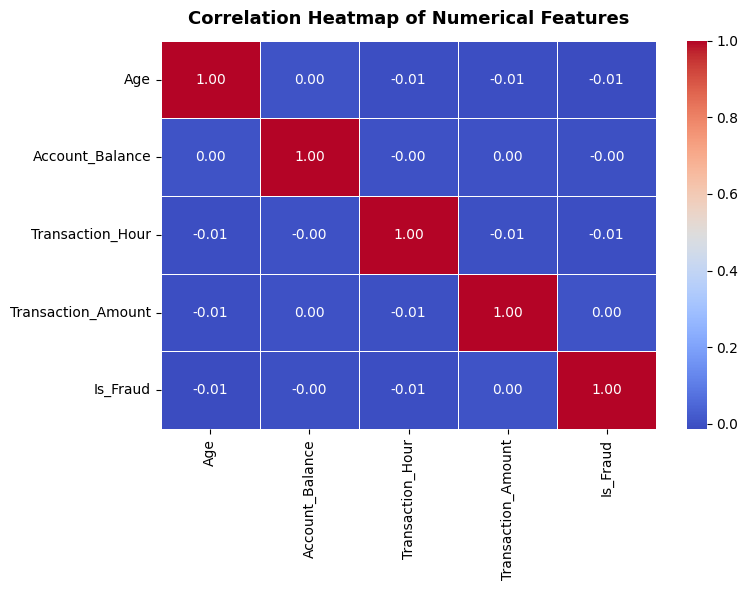

In [5]:
# Extract transaction hour from Transaction_Time
df_clean = df.withColumn("Transaction_Hour", hour(col("Transaction_Time")).cast("double"))

categorical_cols = ["Gender", "Account_Type", "Transaction_Type", "Merchant_Category", "Device_Type"]
numerical_cols = ["Age", "Account_Balance", "Transaction_Hour"]

for c in numerical_cols + ["Transaction_Amount", "Is_Fraud"]:
    df_clean = df_clean.withColumn(c, col(c).cast("double"))

df_model = df_clean.select(*(categorical_cols + numerical_cols + ["Transaction_Amount", "Is_Fraud"])).dropna()

# Correlation Heatmap on numerical features
corr_features = ["Age", "Account_Balance", "Transaction_Hour", "Transaction_Amount", "Is_Fraud"]
corr_sample = df_model.select(*corr_features).sample(fraction=0.1, seed=42).toPandas()
corr_matrix = corr_sample.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Features", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()


### Step 6: Unsupervised Learning - K-Means Clustering
Customer transaction segmentation using `VectorAssembler` and `StandardScaler` (Mean=0, Std=1), evaluated via the Silhouette Score.


In [6]:
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.ml import Pipeline

kmeans_features = ["Age", "Transaction_Amount", "Account_Balance", "Transaction_Hour"]

km_assembler = VectorAssembler(inputCols=kmeans_features, outputCol="km_raw_features")
km_scaler = StandardScaler(inputCol="km_raw_features", outputCol="km_scaled_features", withStd=True, withMean=True)
kmeans = KMeans(featuresCol="km_scaled_features", k=3, seed=42)

km_pipeline = Pipeline(stages=[km_assembler, km_scaler, kmeans])
km_model = km_pipeline.fit(df_model)
km_predictions = km_model.transform(df_model)

km_evaluator = ClusteringEvaluator(featuresCol="km_scaled_features", metricName="silhouette", distanceMeasure="squaredEuclidean")
silhouette = km_evaluator.evaluate(km_predictions)

print(f"K-Means Clustering Silhouette Score (k=3): {silhouette:.4f}")
km_predictions.select("Age", "Transaction_Amount", "Account_Balance", "Transaction_Hour", "prediction").show(5)


K-Means Clustering Silhouette Score (k=3): 0.2822
+----+------------------+---------------+----------------+----------+
| Age|Transaction_Amount|Account_Balance|Transaction_Hour|prediction|
+----+------------------+---------------+----------------+----------+
|60.0|          32415.45|       74557.27|            16.0|         1|
|51.0|           43622.6|       74622.66|            17.0|         2|
|20.0|          63062.56|       66817.99|             3.0|         0|
|57.0|          14000.72|       58177.08|            12.0|         1|
|43.0|          18335.16|       16108.56|            18.0|         1|
+----+------------------+---------------+----------------+----------+
only showing top 5 rows



### Step 7: Feature Encoding & Train/Test Split
Categorical variables are indexed and one-hot encoded for supervised models. The dataset is split into 80% training and 20% testing sets.


In [7]:
from pyspark.ml.feature import StringIndexer, OneHotEncoder

indexers = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in categorical_cols]
encoders = [OneHotEncoder(inputCol=f"{c}_idx", outputCol=f"{c}_vec") for c in categorical_cols]
encoded_cols = [f"{c}_vec" for c in categorical_cols]

train_data, test_data = df_model.randomSplit([0.8, 0.2], seed=42)

print(f"Training Records : {train_data.count()}")
print(f"Testing Records  : {test_data.count()}")


Training Records : 160310


Testing Records  : 39690


### Step 8: Supervised Regression - Linear Regression
Predicting `Transaction_Amount` using customer demographic, temporal, and account characteristics.
Evaluated using $R^2$, RMSE, and MAE, along with an Actual vs. Predicted plot.


R² Score : -0.0003
RMSE     : ₹28,485.82
MAE      : ₹24,659.82


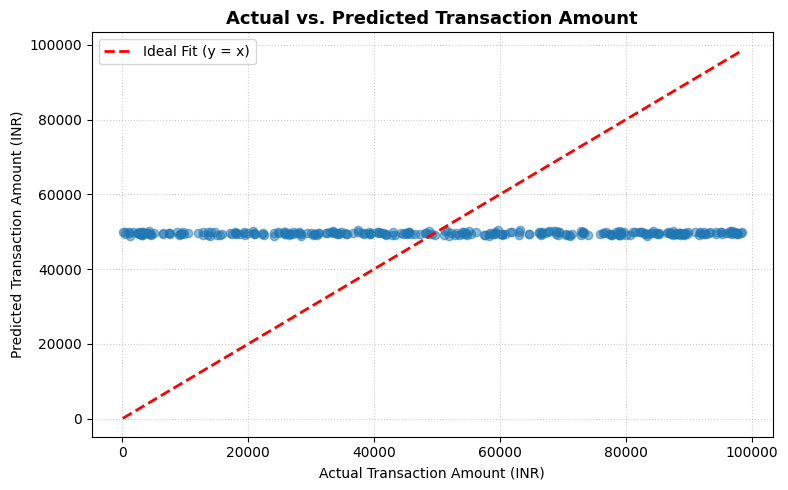

In [8]:
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

reg_features = encoded_cols + numerical_cols
reg_assembler = VectorAssembler(inputCols=reg_features, outputCol="reg_features")

lr = LinearRegression(featuresCol="reg_features", labelCol="Transaction_Amount")
lr_pipeline = Pipeline(stages=indexers + encoders + [reg_assembler, lr])
lr_model = lr_pipeline.fit(train_data)
lr_predictions = lr_model.transform(test_data)

r2 = RegressionEvaluator(labelCol="Transaction_Amount", predictionCol="prediction", metricName="r2").evaluate(lr_predictions)
rmse = RegressionEvaluator(labelCol="Transaction_Amount", predictionCol="prediction", metricName="rmse").evaluate(lr_predictions)
mae = RegressionEvaluator(labelCol="Transaction_Amount", predictionCol="prediction", metricName="mae").evaluate(lr_predictions)

print(f"R² Score : {r2:.4f}")
print(f"RMSE     : ₹{rmse:,.2f}")
print(f"MAE      : ₹{mae:,.2f}")

sample_reg = lr_predictions.select("Transaction_Amount", "prediction").sample(fraction=0.01, seed=42).limit(300).toPandas()

plt.figure(figsize=(8, 5))
plt.scatter(sample_reg["Transaction_Amount"], sample_reg["prediction"], alpha=0.5, color="#1f77b4")
plt.plot([sample_reg["Transaction_Amount"].min(), sample_reg["Transaction_Amount"].max()],
         [sample_reg["Transaction_Amount"].min(), sample_reg["Transaction_Amount"].max()],
         color="red", linestyle="--", linewidth=2, label="Ideal Fit (y = x)")
plt.title("Actual vs. Predicted Transaction Amount", fontsize=13, fontweight="bold")
plt.xlabel("Actual Transaction Amount (INR)")
plt.ylabel("Predicted Transaction Amount (INR)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


### Step 9: Supervised Classification - Fraud Detection Models
Training and comparing four classifiers specified in the syllabus:
1. Logistic Regression
2. Decision Tree Classifier
3. Support Vector Machine (LinearSVC)
4. Gaussian Naive Bayes


In [9]:
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier, LinearSVC, NaiveBayes

class_features = encoded_cols + numerical_cols + ["Transaction_Amount"]
class_assembler = VectorAssembler(inputCols=class_features, outputCol="class_features")

# Logistic Regression
lr_classifier = LogisticRegression(featuresCol="class_features", labelCol="Is_Fraud", maxIter=10)
model_lr = Pipeline(stages=indexers + encoders + [class_assembler, lr_classifier]).fit(train_data)
preds_lr = model_lr.transform(test_data)

# Decision Tree Classifier
dt_classifier = DecisionTreeClassifier(featuresCol="class_features", labelCol="Is_Fraud", maxDepth=5)
model_dt = Pipeline(stages=indexers + encoders + [class_assembler, dt_classifier]).fit(train_data)
preds_dt = model_dt.transform(test_data)

# Support Vector Machine (LinearSVC)
svm_classifier = LinearSVC(featuresCol="class_features", labelCol="Is_Fraud", maxIter=10)
model_svm = Pipeline(stages=indexers + encoders + [class_assembler, svm_classifier]).fit(train_data)
preds_svm = model_svm.transform(test_data)

# Gaussian Naive Bayes
nb_classifier = NaiveBayes(featuresCol="class_features", labelCol="Is_Fraud", modelType="gaussian")
model_nb = Pipeline(stages=indexers + encoders + [class_assembler, nb_classifier]).fit(train_data)
preds_nb = model_nb.transform(test_data)

print("Classification models trained and evaluated on test dataset.")


Classification models trained and evaluated on test dataset.


### Step 10: Performance Matrix & Confusion Matrix
Evaluating model accuracy, F1-scores, and rendering the Confusion Matrix dynamically.


                       Model  Accuracy (%)  F1-Score
         Logistic Regression         94.88    0.9238
               Decision Tree         94.87    0.9238
Support Vector Machine (SVM)         94.88    0.9238
                 Naive Bayes         94.88    0.9238


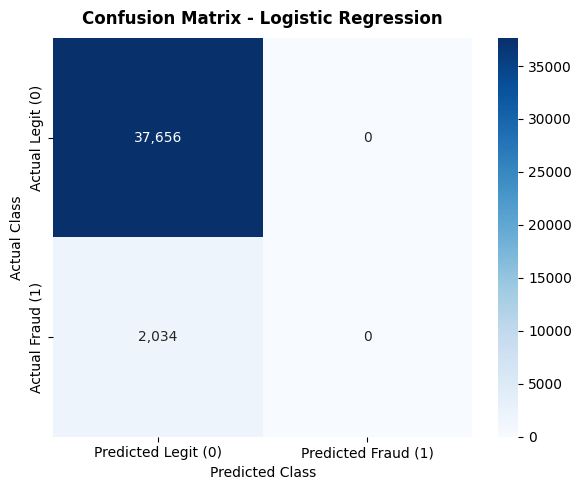

In [10]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

acc_evaluator = MulticlassClassificationEvaluator(labelCol="Is_Fraud", predictionCol="prediction", metricName="accuracy")
f1_evaluator = MulticlassClassificationEvaluator(labelCol="Is_Fraud", predictionCol="prediction", metricName="f1")

models = [
    ("Logistic Regression", preds_lr),
    ("Decision Tree", preds_dt),
    ("Support Vector Machine (SVM)", preds_svm),
    ("Naive Bayes", preds_nb)
]

comparison_records = []
for model_name, predictions in models:
    acc = acc_evaluator.evaluate(predictions) * 100
    f1 = f1_evaluator.evaluate(predictions)
    comparison_records.append({"Model": model_name, "Accuracy (%)": round(acc, 2), "F1-Score": round(f1, 4)})

summary_df = pd.DataFrame(comparison_records)
print(summary_df.to_string(index=False))

# Dynamic Confusion Matrix for Logistic Regression
cm_df = preds_lr.groupBy("Is_Fraud", "prediction").count().toPandas()
cm_matrix = np.zeros((2, 2), dtype=int)

for _, row in cm_df.iterrows():
    actual_idx = int(row["Is_Fraud"])
    pred_idx = int(row["prediction"])
    cm_matrix[actual_idx, pred_idx] = int(row["count"])

cm_display = pd.DataFrame(
    cm_matrix,
    index=["Actual Legit (0)", "Actual Fraud (1)"],
    columns=["Predicted Legit (0)", "Predicted Fraud (1)"]
)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_display, annot=True, fmt=",d", cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression", fontsize=12, fontweight="bold", pad=10)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


### Step 11: Cluster Session Shutdown

In [11]:
spark.stop()
print("SparkSession terminated successfully. Distributed cluster resources released.")


SparkSession terminated successfully. Distributed cluster resources released.
